# EDA & ETL — RSV Admissions, Weekly Hospital Respiratory Data (Pure PySpark)
**File:** `eda_2_09020624025.ipynb`

Notebook ini mengimplementasikan jalur **RSV Admissions** pada flowchart & arsitektur sistem secara murni menggunakan **Apache Spark / PySpark** (tanpa perlu instalasi Hadoop cluster/eksternal):
1. **Data Source & Ingestion:** `Kaggle` (`noeyislearning/weekly-hospital-respiratory-data-and-metrics`) → `Kagglehub` (`Get Data`)
2. **Filter Cabang Flowchart (`RSV Admissions → Yes`):** Menyaring hanya kolom domain RSV Admissions dan kapasitas rawat inap (membuang 150+ kolom COVID-19 & Influenza yang tidak relevan)
3. **ETL Tahap 1 (`DataFrame` → `Data Type Checking` → `Save` → `Local Storage`):** Validasi skema & tipe numerik/tanggal lalu simpan ke Parquet lokal menggunakan writer murni PyArrow/PySpark (bebas error `HADOOP_HOME` di Windows)
4. **ETL Tahap 2 (`Get Data` → `Column Mapping` & `Filter Region Low Quality`):** Standardisasi nama kolom, pemisahan agregat nasional (`USA`), dan penghapusan wilayah kecil dengan pelaporan jarang (`AS, GU, MP, VI, PR`)
5. **Descriptive & Data Quality (`Five-Number Summary`, `Tabulation`, `0 Imputation Missing Value`, `Outliers Check` IQR)**
6. **Feature Engineering (`lag/rolling feature by persentil periode` & `70/100 Spikes label Definition`):** Membentuk fitur lag/rolling per wilayah dan label lonjakan persentil-70 yang konsisten dipakai oleh `model_2` dan `bda_2`
7. **Visualisasi Arsitektur:** `Standard Bar Chart`, `Trend Analysis`, `Multi-series Line Chart`, dan `Bounded Area Chart`

## 0. Instalasi Library
Menggunakan `pyspark`, `kagglehub`, `pandas`, `pyarrow` (untuk baca/tulis Parquet lokal tanpa Hadoop), dan `matplotlib`.

In [1]:
%pip install -q pyspark kagglehub pandas pyarrow matplotlib

Note: you may need to restart the kernel to use updated packages.


## 1. Import Library & Helper I/O Murni PySpark (Tanpa Hadoop)

In [2]:
import os
import shutil
import warnings
import pandas as pd
import matplotlib.pyplot as plt

from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.window import Window

warnings.filterwarnings("ignore", category=FutureWarning)


def save_parquet_pure_spark(spark_df, target_path):
    """Simpan Spark DataFrame ke Parquet lokal tanpa ketergantungan winutils.exe/Hadoop di Windows."""
    parent_dir = os.path.dirname(target_path)
    if parent_dir:
        os.makedirs(parent_dir, exist_ok=True)
    # Bersihkan sisa file/folder kosong dari eksekusi sebelumnya jika ada
    if os.path.isdir(target_path):
        shutil.rmtree(target_path)
    elif os.path.exists(target_path):
        os.remove(target_path)

    if os.name == "nt" and not os.environ.get("HADOOP_HOME"):
        spark_df.toPandas().to_parquet(target_path, index=False)
    else:
        spark_df.write.mode("overwrite").parquet(target_path)

## 2. Inisialisasi Spark Session
Mode lokal murni (`local[*]`) tanpa Hadoop HDFS/YARN.

In [3]:
spark = (
    SparkSession.builder
    .appName("RSVAdmissions_EDA_ETL")
    .master("local[*]")
    .config("spark.sql.shuffle.partitions", "4")
    .config("spark.driver.memory", "4g")
    .config("spark.sql.ansi.enabled", "false")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("ERROR")
spark

## 3. Ingestion: Kaggle → Kagglehub (`Get Data`)
Mengunduh dataset mentah secara otomatis jika belum tersedia di `../data/raw/kaggle/`.

In [4]:
KAGGLE_DATASET = "noeyislearning/weekly-hospital-respiratory-data-and-metrics"
KAGGLE_FILE = "raw_weekly_hospital_respiratory_data_2020_2024.csv"

RAW_KAGGLE_DIR = "../data/raw/kaggle"
RAW_HOSPITAL_PATH = os.path.join(RAW_KAGGLE_DIR, KAGGLE_FILE)
os.makedirs(RAW_KAGGLE_DIR, exist_ok=True)


def download_hospital_dataset():
    if os.path.exists(RAW_HOSPITAL_PATH):
        print(f"-> {KAGGLE_FILE} sudah tersedia di Local Storage, skip download.")
        return
    import kagglehub
    path = kagglehub.dataset_download(KAGGLE_DATASET)
    src = os.path.join(path, KAGGLE_FILE)
    if not os.path.exists(src):
        raise FileNotFoundError(f"{KAGGLE_FILE} tidak ditemukan di {path}. Isi: {os.listdir(path)}")
    shutil.copy2(src, RAW_HOSPITAL_PATH)
    print(f"-> Dataset tersimpan di: {RAW_HOSPITAL_PATH}")


download_hospital_dataset()

-> raw_weekly_hospital_respiratory_data_2020_2024.csv sudah tersedia di Local Storage, skip download.


## 4. Percabangan Flowchart (`RSV Admissions → Yes`) + `Data Type Checking`
Sesuai flowchart, dari 157 kolom dataset respiratori, **hanya jalur `RSV Admissions` yang diambil** (kolom COVID-19, Influenza, dll. dibuang sejak awal sebelum validasi tipe data dan penyimpanan tahap 1).

In [5]:
df_raw_all = spark.read.csv(RAW_HOSPITAL_PATH, header=True, inferSchema=True)
print("Dataset mentah:", df_raw_all.count(), "baris,", len(df_raw_all.columns), "kolom")

# Rapikan spasi pada nama kolom jika ada
df_raw_all = df_raw_all.toDF(*[c.strip() for c in df_raw_all.columns])

# Seleksi khusus cabang flowchart: RSV Admissions -> Yes
RSV_DOMAIN_COLS = [
    "Week Ending Date",
    "Geographic aggregation",
    "Total RSV Admissions",
    "Number of Inpatient Beds",
    "Number of Inpatient Beds Occupied",
    "Percent Hospitals Reporting RSV Admissions",
]
NUMERIC_COLS = [
    "Total RSV Admissions",
    "Number of Inpatient Beds",
    "Number of Inpatient Beds Occupied",
    "Percent Hospitals Reporting RSV Admissions",
]

missing_cols = set(RSV_DOMAIN_COLS) - set(df_raw_all.columns)
if missing_cols:
    raise ValueError(f"Kolom wajib RSV Admissions tidak ditemukan: {missing_cols}")
print(f"[Branch Filter] RSV Admissions -> Yes: menyaring {len(RSV_DOMAIN_COLS)} kolom relevan dari {len(df_raw_all.columns)} kolom total.")

df_rsv_stage1 = df_raw_all.select(*RSV_DOMAIN_COLS)

# Data Type Checking
dtypes = dict(df_rsv_stage1.dtypes)
for c in NUMERIC_COLS:
    t = dtypes[c]
    is_numeric = t in ("int", "bigint", "smallint", "double", "float") or t.startswith("decimal")
    print(f"[Data Type Checking] {c}: {t} -> {'OK' if is_numeric else 'cast ke double'}")
    if not is_numeric:
        df_rsv_stage1 = df_rsv_stage1.withColumn(c, F.col(c).cast("double"))

# Validasi format tanggal Week Ending Date
df_rsv_stage1 = df_rsv_stage1.withColumn("Week Ending Date", F.to_date("Week Ending Date"))
print(f"[Data Type Checking] Week Ending Date: {dict(df_rsv_stage1.dtypes)['Week Ending Date']} -> OK")

Dataset mentah: 12768 baris, 157 kolom
[Branch Filter] RSV Admissions -> Yes: menyaring 6 kolom relevan dari 157 kolom total.
[Data Type Checking] Total RSV Admissions: double -> OK
[Data Type Checking] Number of Inpatient Beds: double -> OK
[Data Type Checking] Number of Inpatient Beds Occupied: double -> OK
[Data Type Checking] Percent Hospitals Reporting RSV Admissions: double -> OK
[Data Type Checking] Week Ending Date: date -> OK


## 5. `Save` → `Local Storage` (Stage 1 Parquet)
Menyimpan data RSV Admissions yang lolos pengecekan tipe data ke Local Storage (`../data/processed/hospital_time_series.parquet`).

In [6]:
PROCESSED_DIR = "../data/processed"
os.makedirs(PROCESSED_DIR, exist_ok=True)

df_rsv_stage1 = (
    df_rsv_stage1
    .withColumn("dataset_id", F.lit("rsv_admissions_weekly"))
    .withColumn("category", F.lit("time_series"))
)

hospital_stage1_path = os.path.join(PROCESSED_DIR, "hospital_time_series.parquet")
save_parquet_pure_spark(df_rsv_stage1, hospital_stage1_path)
print("Tersimpan di Local Storage (tanpa Hadoop):", hospital_stage1_path)

Tersimpan di Local Storage (tanpa Hadoop): ../data/processed\hospital_time_series.parquet


## 6. `Get Data` (Local Storage) → `Column Mapping` & `Filter Region Low Quality`
Membaca ulang dari Local Storage, menstandarkan nama kolom, memisahkan agregat nasional (`USA`), dan memfilter wilayah kecil dengan pelaporan jarang (`AS, GU, MP, VI, PR`).

In [7]:
HOSP_MAP = {
    "Week Ending Date": "week_date",
    "Geographic aggregation": "state",
    "Total RSV Admissions": "rsv_adm",
    "Number of Inpatient Beds Occupied": "inpatient_beds_occupied",
    "Number of Inpatient Beds": "inpatient_beds_total",
    "Percent Hospitals Reporting RSV Admissions": "pct_hosp_reporting_rsv",
}
KEEP_COLS = list(HOSP_MAP.values())

df_hospital = spark.read.parquet(hospital_stage1_path)
for old, new in HOSP_MAP.items():
    df_hospital = df_hospital.withColumnRenamed(old, new)

df_hospital = df_hospital.withColumn("week_date", F.to_date("week_date")).select(*KEEP_COLS)

EXCLUDE_REGIONS = ["USA", "AS", "GU", "MP", "VI", "PR"]
df_national = df_hospital.filter(F.col("state") == "USA")
df_panel = df_hospital.filter(~F.col("state").isin(EXCLUDE_REGIONS))

print("Baris nasional (USA) :", df_national.count())
print("Baris panel per-state:", df_panel.count(), "| jumlah region aktif:", df_panel.select("state").distinct().count())
df_panel.printSchema()

Baris nasional (USA) : 224
Baris panel per-state: 11424 | jumlah region aktif: 51
root
 |-- week_date: date (nullable = true)
 |-- state: string (nullable = true)
 |-- rsv_adm: double (nullable = true)
 |-- inpatient_beds_occupied: double (nullable = true)
 |-- inpatient_beds_total: double (nullable = true)
 |-- pct_hosp_reporting_rsv: double (nullable = true)



## 7. Describe — `Five-Number Descriptive Summary Statistics` & `Tabulation`
Ringkasan lima angka (`min`, `25%`, `50%`, `75%`, `max`) dan tabulasi kelengkapan pelaporan RSV per tahun.

In [8]:
print("=== Five-Number Summary: RSV Admissions (panel per-state, sebelum imputasi) ===")
df_panel.select("rsv_adm").summary("min", "25%", "50%", "75%", "max").show()

print("=== Tabulasi Pelaporan RSV per Tahun ===")
(
    df_panel.withColumn("year", F.year("week_date"))
    .groupBy("year")
    .agg(
        F.count("*").alias("total_baris"),
        F.count("rsv_adm").alias("n_rsv_terlapor"),
        F.round(F.avg("pct_hosp_reporting_rsv"), 2).alias("avg_pct_rs_lapor"),
    )
    .orderBy("year")
    .show()
)

print("Rentang tanggal keseluruhan:")
df_panel.select(F.min("week_date").alias("mulai"), F.max("week_date").alias("akhir")).show()

=== Five-Number Summary: RSV Admissions (panel per-state, sebelum imputasi) ===
+-------+-------+
|summary|rsv_adm|
+-------+-------+
|    min|    0.0|
|    25%|    0.0|
|    50%|    0.0|
|    75%|    2.0|
|    max|  463.0|
+-------+-------+

=== Tabulasi Pelaporan RSV per Tahun ===
+----+-----------+--------------+----------------+
|year|total_baris|n_rsv_terlapor|avg_pct_rs_lapor|
+----+-----------+--------------+----------------+
|2020|       1071|             0|             0.0|
|2021|       2652|             0|             0.0|
|2022|       2703|             0|             0.0|
|2023|       2652|           217|            0.01|
|2024|       2346|          1778|            0.12|
+----+-----------+--------------+----------------+

Rentang tanggal keseluruhan:
+----------+----------+
|     mulai|     akhir|
+----------+----------+
|2020-08-08|2024-11-16|
+----------+----------+



## 8. `0 Imputation Missing Value` & `Outliers Check` (`Range and Interquartile`)
Pelaporan wajib RSV dimulai Oktober 2023; nilai `NULL` sebelum periode tersebut menandakan belum ada pelaporan sehingga diimputasi `0`. Outlier dideteksi dengan metode IQR pada periode pelaporan aktif namun **tidak dihapus/di-cap** karena lonjakan musiman merupakan sinyal target prediksi.

In [9]:
n_null = df_panel.filter(F.col("rsv_adm").isNull()).count()
print(f"NULL rsv_adm sebelum imputasi: {n_null} dari {df_panel.count()} baris")

REPORTING_START = df_panel.filter(F.col("rsv_adm").isNotNull()).agg(F.min("week_date")).first()[0]
print("Tanggal awal pelaporan RSV aktif:", REPORTING_START)

df_panel = df_panel.fillna({"rsv_adm": 0.0})
df_national = df_national.fillna({"rsv_adm": 0.0})

# Outliers Check (IQR pada periode pelaporan RSV aktif)
df_reported = df_panel.filter(F.col("week_date") >= F.lit(REPORTING_START))
q1, q3 = df_reported.approxQuantile("rsv_adm", [0.25, 0.75], 0.01)
iqr = q3 - q1
lower_bound, upper_bound = q1 - 1.5 * iqr, q3 + 1.5 * iqr
n_reported = df_reported.count()
n_outliers = df_reported.filter((F.col("rsv_adm") < lower_bound) | (F.col("rsv_adm") > upper_bound)).count()

print(f"IQR Summary -> Q1={q1:.1f}, Q3={q3:.1f}, IQR={iqr:.1f}, Upper Bound={upper_bound:.1f}")
print(f"Outlier terdeteksi: {n_outliers}/{n_reported} baris ({n_outliers / n_reported:.1%}) -> dipertahankan sebagai sinyal lonjakan.")

NULL rsv_adm sebelum imputasi: 9429 dari 11424 baris
Tanggal awal pelaporan RSV aktif: 2023-10-07
IQR Summary -> Q1=0.0, Q3=0.0, IQR=0.0, Upper Bound=0.0
Outlier terdeteksi: 732/3009 baris (24.3%) -> dipertahankan sebagai sinyal lonjakan.


## 9. Feature Engineering: `lag/rolling feature by persentil periode` & `70/100 Spikes label Definition`
Seluruh fitur lag, rolling mean 4 minggu, rasio okupansi tempat tidur (`bed_occ_ratio_lag1`), persentase perubahan mingguan (`pct_change`), dan label lonjakan persentil-70 (`spike_label`) dihitung **per-wilayah** (`Window.partitionBy("state")`) lalu disimpan ke `features_hospital_timeseries.parquet` agar langsung dipakai tanpa perbedaan definisi di `model_2` dan `bda_2`.

In [10]:
df_panel = df_panel.withColumn(
    "bed_occ_ratio",
    F.when(F.col("inpatient_beds_total") > 0, F.col("inpatient_beds_occupied") / F.col("inpatient_beds_total")),
)

w = Window.partitionBy("state").orderBy("week_date")

df_feat = (
    df_panel
    .withColumn("lag_1", F.lag("rsv_adm", 1).over(w))
    .withColumn("lag_2", F.lag("rsv_adm", 2).over(w))
    .withColumn("rolling_mean_4w", F.avg("rsv_adm").over(w.rowsBetween(-4, -1)))
    .withColumn("bed_occ_ratio_lag1", F.lag("bed_occ_ratio", 1).over(w))
    .withColumn("week_of_year", F.weekofyear("week_date"))
    .withColumn("month", F.month("week_date"))
    .withColumn("pct_change", F.when(F.col("lag_1") > 0, (F.col("rsv_adm") - F.col("lag_1")) / F.col("lag_1")))
)

df_feat = df_feat.dropna(subset=["lag_1", "lag_2", "rolling_mean_4w", "bed_occ_ratio_lag1", "pct_change"])
df_feat = df_feat.filter((F.col("bed_occ_ratio_lag1") >= 0) & (F.col("bed_occ_ratio_lag1") <= 1))

# 70/100 Spikes label Definition (persentil ke-70 pct_change)
SPIKE_THRESHOLD = df_feat.approxQuantile("pct_change", [0.70], 0.01)[0]
df_feat = df_feat.withColumn("spike_label", (F.col("pct_change") > F.lit(SPIKE_THRESHOLD)).cast("int"))

print(f"Threshold lonjakan (persentil-70 pct_change): {SPIKE_THRESHOLD:.4f} ({SPIKE_THRESHOLD:.1%})")
print("Total baris siap-model:", df_feat.count(), "| Jumlah region:", df_feat.select("state").distinct().count())
df_feat.select("week_date", "state", "rsv_adm", "lag_1", "rolling_mean_4w", "bed_occ_ratio_lag1", "pct_change", "spike_label").show(10)

features_hospital_path = os.path.join(PROCESSED_DIR, "features_hospital_timeseries.parquet")
save_parquet_pure_spark(df_feat, features_hospital_path)
print("Fitur siap-model tersimpan di:", features_hospital_path)

Threshold lonjakan (persentil-70 pct_change): 0.2500 (25.0%)
Total baris siap-model: 684 | Jumlah region: 51
+----------+-----+-------+-----+---------------+------------------+----------+-----------+
| week_date|state|rsv_adm|lag_1|rolling_mean_4w|bed_occ_ratio_lag1|pct_change|spike_label|
+----------+-----+-------+-----+---------------+------------------+----------+-----------+
|2024-01-06|   AK|    3.0|  4.0|            1.0|0.7147147147147147|     -0.25|          0|
|2024-01-13|   AK|    0.0|  3.0|           1.75|0.7505551443375278|      -1.0|          0|
|2024-02-03|   AK|    0.0|  3.0|            1.5|0.7556859867938371|      -1.0|          0|
|2024-02-17|   AK|    0.0|  1.0|            1.0|0.7638483965014577|      -1.0|          0|
|2024-03-09|   AK|    1.0|  1.0|            0.5|0.7385524372230429|       0.0|          0|
|2024-03-16|   AK|    1.0|  1.0|            0.5|0.7437037037037038|       0.0|          0|
|2024-03-23|   AK|    1.0|  1.0|           0.75|0.7298474945533769|     

## 10. Visualisasi EDA & Arsitektur (`Standard Bar Chart`, `Trend Analysis`, `Multi-series Line Chart`, `Bounded Area Chart`)

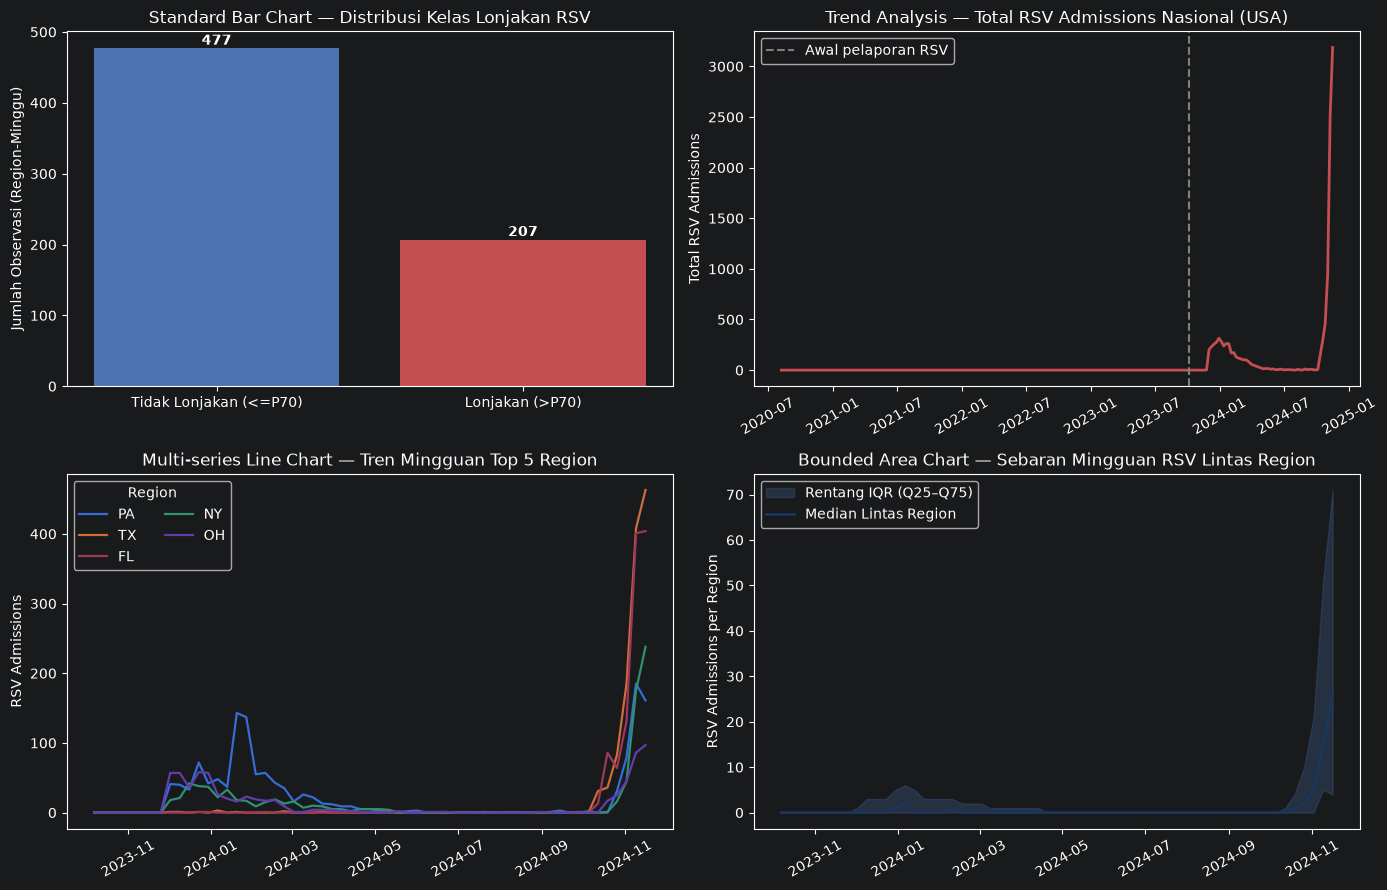

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# 1. Standard Bar Chart: Distribusi Kelas Lonjakan
pdf_class = df_feat.groupBy("spike_label").count().orderBy("spike_label").toPandas()
pdf_class["kelas"] = pdf_class["spike_label"].map({0: "Tidak Lonjakan (<=P70)", 1: "Lonjakan (>P70)"})
axes[0, 0].bar(pdf_class["kelas"], pdf_class["count"], color=["#4C72B0", "#C44E52"])
axes[0, 0].set_title("Standard Bar Chart — Distribusi Kelas Lonjakan RSV")
axes[0, 0].set_ylabel("Jumlah Observasi (Region-Minggu)")
for idx, row in pdf_class.iterrows():
    axes[0, 0].text(idx, row["count"] + 5, str(row["count"]), ha="center", fontweight="bold")

# 2. Trend Analysis: Tren Mingguan RSV Nasional
pdf_trend = df_national.select("week_date", "rsv_adm").orderBy("week_date").toPandas()
pdf_trend["week_date"] = pd.to_datetime(pdf_trend["week_date"])
axes[0, 1].plot(pdf_trend["week_date"], pdf_trend["rsv_adm"], color="#C44E52", linewidth=2)
axes[0, 1].axvline(pd.to_datetime(REPORTING_START), color="gray", linestyle="--", label="Awal pelaporan RSV")
axes[0, 1].set_title("Trend Analysis — Total RSV Admissions Nasional (USA)")
axes[0, 1].set_ylabel("Total RSV Admissions")
axes[0, 1].tick_params(axis="x", rotation=30)
axes[0, 1].legend()

# 3. Multi-series Line Chart: Top 5 Region dengan Rata-Rata Admisi RSV Tertinggi
df_active = df_panel.filter(F.col("week_date") >= F.lit(REPORTING_START))
top5_states = [
    r["state"]
    for r in df_active.groupBy("state").agg(F.avg("rsv_adm").alias("m")).orderBy(F.desc("m")).limit(5).collect()
]
pdf_multi = (
    df_active.filter(F.col("state").isin(top5_states))
    .select("week_date", "state", "rsv_adm")
    .orderBy("week_date")
    .toPandas()
)
pdf_multi["week_date"] = pd.to_datetime(pdf_multi["week_date"])
for st in top5_states:
    sub = pdf_multi[pdf_multi["state"] == st]
    axes[1, 0].plot(sub["week_date"], sub["rsv_adm"], label=st, linewidth=1.6)
axes[1, 0].set_title("Multi-series Line Chart — Tren Mingguan Top 5 Region")
axes[1, 0].set_ylabel("RSV Admissions")
axes[1, 0].tick_params(axis="x", rotation=30)
axes[1, 0].legend(title="Region", ncol=2)

# 4. Bounded Area Chart: Rentang Kuartil (Q25-Q75) & Median Lintas 51 Region
pdf_band = (
    df_active.groupBy("week_date")
    .agg(
        F.percentile_approx("rsv_adm", 0.25).alias("q25"),
        F.percentile_approx("rsv_adm", 0.50).alias("median"),
        F.percentile_approx("rsv_adm", 0.75).alias("q75"),
    )
    .orderBy("week_date")
    .toPandas()
)
pdf_band["week_date"] = pd.to_datetime(pdf_band["week_date"])
axes[1, 1].fill_between(pdf_band["week_date"], pdf_band["q25"], pdf_band["q75"], color="#4C72B0", alpha=0.25, label="Rentang IQR (Q25–Q75)")
axes[1, 1].plot(pdf_band["week_date"], pdf_band["median"], color="#1B365D", linewidth=2, label="Median Lintas Region")
axes[1, 1].set_title("Bounded Area Chart — Sebaran Mingguan RSV Lintas Region")
axes[1, 1].set_ylabel("RSV Admissions per Region")
axes[1, 1].tick_params(axis="x", rotation=30)
axes[1, 1].legend()

plt.tight_layout()
plt.show()

## 11. Ringkasan ETL & EDA
- Pipeline berjalan murni di atas **PySpark** tanpa memerlukan instalasi Hadoop cluster.
- Cabang flowchart **`RSV Admissions → Yes`** menyaring 6 kolom relevan dari 157 kolom mentah, memvalidasi tipe data, dan menyimpan `hospital_time_series.parquet` serta `features_hospital_timeseries.parquet`.
- Dataset siap dilanjutkan ke `model_2_09020624025.ipynb` untuk pelatihan & tuning **Random Forest Classifier**.